# Onder Nul: a two-day warning for negative electricity prices

**Veritas AI International High School Hackathon 2026 · AI + Finance · Vayun Godara**

In the Netherlands the hourly electricity price sometimes drops **below zero** ("onder nul"),
mostly on sunny, windy days when there is more power than people need. If you have solar panels
and a dynamic contract, exporting power in those hours *costs* you money. If you can plan ahead,
those are also the best hours to charge a car or run the washing machine.

Tomorrow's prices are published every day around 13:00. This notebook asks a harder question:
**can a model warn you two days ahead which hours will go negative, using only what was known at that time?**

The plan:
1. Load prices and *archived* weather forecasts.
2. Build a table where each row is one hour and every input was known 48 hours earlier.
3. Score simple baselines (rules anyone could use without AI).
4. Train a model, and measure how much each improvement adds.
5. Ask our own questions: how far ahead does it work, and where does it fail?
6. Turn the forecast into a money decision and check whether it would have paid off.

*This project is a prototype and is not financial advice.*

In [1]:
import json, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve, precision_score, recall_score

DATA = Path("data")
DATA.mkdir(exist_ok=True)
START, END = "2024-02-15", "2026-11-13"  # fixed dates so the results can be reproduced
TZ = "Europe/Amsterdam"
plt.rcParams.update({"figure.figsize": (9, 3.5), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})


def get_json(url):
    """Download JSON, waiting and retrying a few times if the server is busy."""
    for attempt in range(5):
        r = requests.get(url, timeout=90)
        if r.ok:
            return r.json()
        time.sleep(15 * (attempt + 1))
    r.raise_for_status()

## 1. Prices

Day-ahead prices for the Dutch bidding zone come from [energy-charts.info](https://api.energy-charts.info)
(Fraunhofer ISE, data from Bundesnetzagentur | SMARD.de, licence CC BY 4.0). They are wholesale prices in
euros per megawatt-hour (EUR/MWh), before tax. 100 EUR/MWh is 10 cents per kWh.

Recent prices come in 15-minute steps, so we average everything to one price per hour.
The file is saved in `data/` so the notebook runs the same way every time.

In [2]:
def load_prices():
    f = DATA / "prices.csv"
    if not f.exists():
        parts = []
        for a, b in [(START, "2024-12-31"), ("2025-01-01", "2025-12-31"), ("2026-01-01", END)]:
            d = get_json(f"https://api.energy-charts.info/price?bzn=NL&start={a}&end={b}")
            parts.append(pd.Series(d["price"], index=pd.to_datetime(d["unix_seconds"], unit="s", utc=True)))
            time.sleep(5)
        s = pd.concat(parts).dropna()
        s[~s.index.duplicated()].resample("1h").mean().rename("price").rename_axis("time").round(4).to_csv(f)
    return pd.read_csv(f, index_col="time", parse_dates=True)["price"]


price = load_prices()
print(f"{len(price):,} hours from {price.index[0]:%d %b %Y} to {price.index[-1]:%d %b %Y}, missing: {price.isna().sum()}")
print("Hours below zero per year:", (price < 0).groupby(price.index.year).sum().to_dict())

24,072 hours from 14 Feb 2024 to 13 Nov 2026, missing: 0
Hours below zero per year: {2024: 445, 2025: 584, 2026: 404}


Negative hours are rare (about 1 hour in 20) and they are not spread evenly.
The chart below counts them by month and hour of day. Most happen around midday from April to September:
that is solar power. A few happen at night: that is wind.

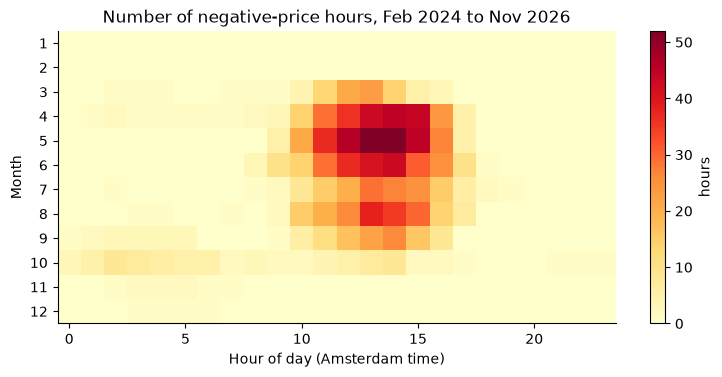

In [3]:
local = price.index.tz_convert(TZ)
grid = (price < 0).groupby([local.month, local.hour]).sum().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(grid, aspect="auto", cmap="YlOrRd")
ax.set(xlabel="Hour of day (Amsterdam time)", ylabel="Month", yticks=range(len(grid)), yticklabels=grid.index, title="Number of negative-price hours, Feb 2024 to Nov 2026")
ax.grid(False)
fig.colorbar(im, label="hours")
plt.show()

## 2. Weather forecasts, as they looked at the time

This is the most important choice in the project. It would be cheating to train on the weather that
*actually happened*, because two days ahead nobody knows that. Open-Meteo's
[Previous Runs API](https://open-meteo.com/en/docs/previous-runs-api) (CC BY 4.0) stores old forecasts:
`shortwave_radiation_previous_day2` is the sunshine forecast for an hour, **as it was predicted 2 days before**.

We use three places, because Dutch prices depend on more than Dutch weather:
- **De Bilt** (middle of the Netherlands): sun on Dutch roofs.
- **North Sea**, off the Dutch coast: offshore wind farms.
- **Central Germany**: the Dutch and German markets are connected, so German sun and wind move Dutch prices.

For each place we download sunshine (W/m²), wind speed at 100 m (km/h) and temperature (°C), predicted 1 to 7 days ahead.

In [4]:
PLACES = {"nl": (52.10, 5.18), "sea": (52.60, 3.90), "de": (51.50, 9.90)}
WX = {"shortwave_radiation": "sun", "wind_speed_100m": "wind", "temperature_2m": "temp"}  # API name: our short name
LEADS = range(1, 8)


def load_weather():
    f = DATA / "weather_forecasts.csv.gz"
    if not f.exists():
        cols = {}
        for place, (lat, lon) in PLACES.items():
            for lead in LEADS:
                names = [f"{v}_previous_day{lead}" for v in WX] + (list(WX) if lead == 1 else [])
                h = get_json(
                    "https://previous-runs-api.open-meteo.com/v1/forecast"
                    f"?latitude={lat}&longitude={lon}&hourly={','.join(names)}&start_date={START}&end_date={END}&timezone=UTC"
                )["hourly"]
                idx = pd.to_datetime(h["time"], utc=True)
                for n in names:
                    # short column names: nl_sun_d2 = sunshine at De Bilt, forecast 2 days ahead; nl_sun_d0 = latest estimate
                    v, _, d = n.partition("_previous_day")
                    cols[f"{place}_{WX[v]}_d{d or 0}"] = pd.Series(h[n], index=idx)
                time.sleep(1)
        pd.DataFrame(cols).rename_axis("time").to_csv(f)
    return pd.read_csv(f, index_col="time", parse_dates=True)


wx = load_weather()
print(wx.shape, "columns like", list(wx.columns[:4]))
print("First date with a forecast, by days ahead:", {d: f"{wx[f'nl_sun_d{d}'].first_valid_index():%Y-%m-%d}" for d in LEADS})

(24072, 72) columns like ['nl_sun_d1', 'nl_wind_d1', 'nl_temp_d1', 'nl_sun_d0']
First date with a forecast, by days ahead: {1: '2024-02-15', 2: '2024-02-15', 3: '2024-02-15', 4: '2024-02-15', 5: '2024-02-15', 6: '2024-02-15', 7: '2024-03-12'}


## 3. One table, with nothing from the future

Each row is one hour. The thing we want to predict is `neg`: was the price below zero in that hour?
For a forecast made `k` days ahead, every input must have been known `24 × k` hours earlier:
(The weather forecast for 14:00 on Saturday is the one made at 14:00 on Thursday, so the warning for the
whole of Saturday is complete by Thursday night.)

| Input | Meaning |
|---|---|
| `hour`, `weekday`, `dayofyear` | The calendar. Known forever in advance. |
| `price_then` | Price of the same hour, `k` days earlier. |
| `price_day_mean`, `neg_hours_day` | Average price and number of negative hours in the 24 hours before that. |
| `price_week_ago` | Price of the same hour, 7 days earlier. |
| `nl_sun`, `sea_wind`, `de_sun`, ... | The weather forecast for this hour, made `k` days ahead. |

In [5]:
CAL = ["hour", "weekday", "dayofyear"]
PAST = ["price_then", "price_day_mean", "neg_hours_day", "price_week_ago"]
W_NL, W_SEA, W_DE = (["{}_{}".format(p, v) for v in ("sun", "wind", "temp")] for p in PLACES)


FIRST_HOUR = wx["nl_sun_d7"].first_valid_index() + pd.Timedelta(days=8)  # same start for every forecast distance


def make_table(k, price=price, wx=wx):
    """One row per hour; every input was known k days (24*k hours) before that hour."""
    lag = 24 * k
    t = pd.DataFrame({"price": price, "neg": (price < 0).astype(int)})
    local = t.index.tz_convert(TZ)
    t["hour"], t["weekday"], t["dayofyear"] = local.hour, local.day_of_week, local.day_of_year
    t["price_then"] = price.shift(lag)
    t["price_day_mean"] = price.shift(lag).rolling(24).mean()
    t["neg_hours_day"] = (price < 0).astype(float).shift(lag).rolling(24).sum()
    t["price_week_ago"] = price.shift(168)
    forecast = wx[[c for c in wx if c.endswith(f"_d{k}")]].rename(columns=lambda c: c.rsplit("_", 1)[0])
    t = t.join(forecast).join(wx["nl_sun_d0"].rename("sun_actual"))
    return t[FIRST_HOUR:].dropna(subset=t.columns.drop("price"))


table = make_table(2)
table.tail(3)

,price,neg,hour,weekday,dayofyear,price_then,price_day_mean,neg_hours_day,price_week_ago,nl_sun,nl_wind,nl_temp,sea_sun,sea_wind,sea_temp,de_sun,de_wind,de_temp,sun_actual
time,,,,,,,,,,,,,,,,,,,
2026-11-13 20:00:00+00:00,246.1075,0,21,4,317,292.5675,309.532917,0.0,294.2925,0.0,17.8,4.9,0.0,26.6,9.8,0.0,27.2,4.0,0.0
2026-11-13 21:00:00+00:00,216.0300,0,22,4,317,250.0250,309.452396,0.0,276.2350,0.0,14.8,5.2,0.0,24.4,9.5,0.0,25.4,3.9,0.0
2026-11-13 22:00:00+00:00,199.2775,0,23,4,317,215.1050,309.282604,0.0,252.5825,0.0,16.6,5.5,0.0,22.1,9.3,0.0,24.4,3.2,0.0


**Leak check.** A model that secretly sees the future looks brilliant and is useless. So we test the table itself:
replace every price after 1 June 2026 with nonsense and rebuild the table. The inputs for the next 48 hours must
stay exactly the same, because a two-day forecast for those hours is not allowed to use any of the replaced prices.
(This checks the price inputs. For the weather inputs we rely on Open-Meteo's archive of old forecasts.)

In [6]:
INPUTS = CAL + PAST + W_NL + W_SEA + W_DE
cut = pd.Timestamp("2026-06-01", tz="UTC")
nonsense = price.where(price.index <= cut, 999.0)
before, after = make_table(2)[INPUTS], make_table(2, nonsense)[INPUTS]
two_days = slice(cut, cut + pd.Timedelta(hours=48))
later = slice(cut + pd.Timedelta(hours=49), None)
assert before[two_days].equals(after[two_days]), "an input used a price from the future"
assert not before[later].equals(after[later]), "the check itself is broken"
print("Leak check passed: no input for an hour uses a price from less than 48 hours before it.")

Leak check passed: no input for an hour uses a price from less than 48 hours before it.


## 4. Splitting by date

We never shuffle the hours. Shuffling would let the model learn from Tuesday to predict Monday, which is
impossible in real life and makes results look better than they are.

- **Train** (until June 2025): the model learns from these hours.
- **Validation** (July to December 2025): a practice exam. We use it to choose settings.
- **Test** (all of 2026): the final exam. Nothing is chosen using these hours.

In [7]:
VAL_START, TEST_START = "2025-07-01", "2026-01-01"


def split(t):
    return t[t.index < VAL_START], t[(t.index >= VAL_START) & (t.index < TEST_START)], t[t.index >= TEST_START]


train, val, test = split(table)
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:11s}{len(part):6,} hours, {part.neg.sum():4} negative ({part.neg.mean():.1%}), {part.index[0]:%d %b %Y} to {part.index[-1]:%d %b %Y}")

train      11,209 hours,  842 negative (7.5%), 20 Mar 2024 to 30 Jun 2025
validation  4,416 hours,  176 negative (4.0%), 01 Jul 2025 to 31 Dec 2025
test        7,607 hours,  404 negative (5.3%), 01 Jan 2026 to 13 Nov 2026


## 5. Baselines: rules that need no AI

About 95% of hours are not negative, so a "model" that always says "not negative" is 95% accurate and
completely useless. That is why we do not report accuracy. Instead:

- **Precision**: of the hours we warned about, what share really went negative? (Low precision = false alarms.)
- **Recall**: of the hours that really went negative, what share did we warn about? (Low recall = missed hours.)
- **F1**: one number that is only high when both precision and recall are high.

The baselines are simple rules a person could follow two days ahead:
1. Never warn.
2. Warn if the same hour was negative two days ago (the newest price we know).
3. Warn if the same hour was negative a week ago (same weekday).
4. Warn on a weekend hour when the forecast says it will be very sunny. The sunshine cut-off is tuned on the data before 2026.

In [8]:
def score(y, flag):
    return {"precision": precision_score(y, flag, zero_division=0), "recall": recall_score(y, flag), "F1": f1_score(y, flag), "warnings": int(flag.sum())}


def sunny_weekend(t, cut):
    return (t.nl_sun > cut) & (t.weekday >= 5)


before_test = pd.concat([train, val])
SUN_CUT = max(range(100, 800, 50), key=lambda c: f1_score(before_test.neg, sunny_weekend(before_test, c)))
baselines = {
    "Never warn": np.zeros(len(test), bool),
    "Same hour 2 days ago was negative": test.price_then < 0,
    "Same hour last week was negative": test.price_week_ago < 0,
    f"Weekend and forecast sun > {SUN_CUT} W/m²": sunny_weekend(test, SUN_CUT),
}
results = pd.DataFrame({name: score(test.neg, flag) for name, flag in baselines.items()}).T
results.round(3)

,precision,recall,F1,warnings
Never warn,0.000,0.000,0.000,0.0
Same hour 2 days ago was negative,0.309,0.309,0.309,404.0
Same hour last week was negative,0.381,0.381,0.381,404.0
Weekend and forecast sun > 350 W/m²,0.471,0.537,0.502,461.0


## 6. The model

We use **gradient boosting** (`HistGradientBoostingClassifier` from scikit-learn). It builds a few hundred small
decision trees, each a chain of yes/no questions such as "is forecast sunshine above 400?" and
"is it a weekend?". Every new tree tries to fix the mistakes of the trees before it. The output is a
probability between 0 and 1 that the hour goes negative.

Two choices are made on the **validation** months, never on the test year:
- **Which inputs to use.** We add them group by group and keep a group only if it helps on validation.
- **The warning threshold.** We warn when the probability is above a cut-off, and choose the cut-off with the best F1.

After that we retrain on train + validation together and open the test year.

*Average precision* (AP) summarises precision over all possible thresholds. A random guess scores about 0.05 here (the share of negative hours), a perfect model 1.0.

In [9]:
def boosting():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0)


def run(cols, k=2, new=boosting):
    """Choose the threshold on validation, retrain on everything before 2026, predict the test year."""
    t = make_table(k)
    tr, va, te = split(t)
    p_val = new().fit(tr[cols], tr.neg).predict_proba(va[cols])[:, 1]
    thr = max(np.arange(0.05, 0.95, 0.05), key=lambda c: f1_score(va.neg, p_val >= c))
    model = new().fit(pd.concat([tr, va])[cols], pd.concat([tr, va]).neg)
    te = te.assign(prob=model.predict_proba(te[cols])[:, 1])
    te["flag"] = te.prob >= thr
    return {"model": model, "thr": thr, "val_AP": average_precision_score(va.neg, p_val), "test": te, "cols": cols}


steps = {
    "A. Calendar + past prices": CAL + PAST,
    "B. A + Dutch weather forecast": CAL + PAST + W_NL,
    "C. B + North Sea wind forecast": CAL + PAST + W_NL + W_SEA,
    "D. C + German weather forecast": CAL + PAST + W_NL + W_SEA + W_DE,
}
runs = {name: run(cols) for name, cols in steps.items()}
ablation = pd.DataFrame(
    {name: {"validation AP": r["val_AP"], "threshold": r["thr"], "test AP": average_precision_score(r["test"].neg, r["test"].prob), **score(r["test"].neg, r["test"].flag)} for name, r in runs.items()}
).T
ablation.round(3)

,validation AP,threshold,test AP,precision,recall,F1,warnings
A. Calendar + past prices,0.220,0.25,0.466,0.403,0.601,0.483,603.0
B. A + Dutch weather forecast,0.458,0.15,0.650,0.485,0.705,0.575,588.0
C. B + North Sea wind forecast,0.512,0.40,0.670,0.604,0.634,0.618,424.0
D. C + German weather forecast,0.543,0.40,0.736,0.645,0.666,0.655,417.0


In [10]:
BEST = ablation["validation AP"].idxmax()  # chosen on validation only
final = runs[BEST]
pred = final["test"]
print("Chosen on validation:", BEST, "| threshold:", round(final["thr"], 2))
results.loc["Model " + BEST] = score(pred.neg, pred.flag)
results.round(3)

Chosen on validation: D. C + German weather forecast | threshold: 0.4


,precision,recall,F1,warnings
Never warn,0.000,0.000,0.000,0.0
Same hour 2 days ago was negative,0.309,0.309,0.309,404.0
Same hour last week was negative,0.381,0.381,0.381,404.0
Weekend and forecast sun > 350 W/m²,0.471,0.537,0.502,461.0
Model D. C + German weather forecast,0.645,0.666,0.655,417.0


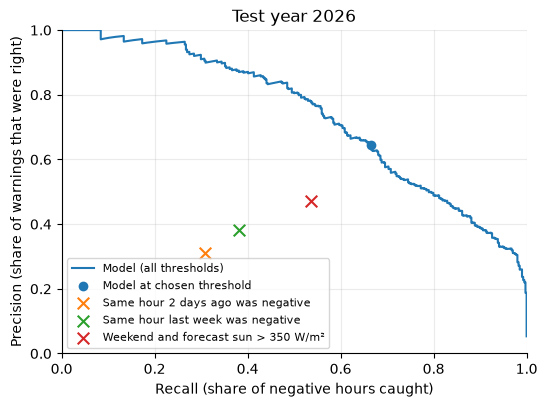

In [11]:
prec, rec, _ = precision_recall_curve(pred.neg, pred.prob)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(rec, prec, label="Model (all thresholds)")
ax.scatter(results.loc["Model " + BEST, "recall"], results.loc["Model " + BEST, "precision"], zorder=3, label="Model at chosen threshold")
for name in list(baselines)[1:]:
    ax.scatter(results.loc[name, "recall"], results.loc[name, "precision"], marker="x", s=70, label=name)
ax.set(xlabel="Recall (share of negative hours caught)", ylabel="Precision (share of warnings that were right)", title="Test year 2026", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8)
plt.show()

### Two checks on that result

**Could the gap be luck?** There is only one test year. To see how much the scores depend on which days happened
to be in it, we rebuild the test year 1,000 times by drawing its days at random, with repeats (a *bootstrap*),
and score the model and the best rule on each version. If the model wins almost every time, the gap does not
hang on a few lucky days. It does not tell us how the model would do in a different year.

In [12]:
def daily_counts(flag):
    """For each test day: hits, false alarms and misses."""
    y = pred.neg.astype(bool)
    counts = pd.DataFrame({"hit": flag & y, "false": flag & ~y, "miss": ~flag & y})
    return counts.groupby(pred.index.tz_convert(TZ).date).sum().to_numpy()


f1_from = lambda c: 2 * c[..., 0] / (2 * c[..., 0] + c[..., 1] + c[..., 2])  # F1 written with hits, false alarms and misses
m, r = daily_counts(pred.flag), daily_counts(sunny_weekend(pred, SUN_CUT))
draws = np.random.default_rng(0).integers(0, len(m), size=(1000, len(m)))  # 1,000 made-up test years, as lists of day numbers
f1_m, f1_r = f1_from(m[draws].sum(axis=1)), f1_from(r[draws].sum(axis=1))
print(f"Model F1 {f1_from(m.sum(axis=0)):.2f}; 95% of the resampled years fall between {np.percentile(f1_m, 2.5):.2f} and {np.percentile(f1_m, 97.5):.2f}")
print(f"Best rule F1 {f1_from(r.sum(axis=0)):.2f}; 95% fall between {np.percentile(f1_r, 2.5):.2f} and {np.percentile(f1_r, 97.5):.2f}")
print(f"The model beats the rule in {(f1_m > f1_r).mean():.1%} of the resampled years")

Model F1 0.66; 95% of the resampled years fall between 0.59 and 0.71
Best rule F1 0.50; 95% fall between 0.43 and 0.57
The model beats the rule in 100.0% of the resampled years


**Does it need hundreds of trees?** We train one small decision tree on the same inputs, with its warning threshold
chosen on validation in the same way. One tree is a single chain of yes/no questions. Boosting adds up a few hundred.

In [13]:
one_tree = run(final["cols"], new=lambda: DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=0))["test"]
simpler = pd.DataFrame({"One small decision tree": score(one_tree.neg, one_tree.flag), f"Gradient boosting ({final['model'].n_iter_} trees)": score(pred.neg, pred.flag)}).T
simpler.round(3)

,precision,recall,F1,warnings
One small decision tree,0.309,0.829,0.450,1084.0
Gradient boosting (230 trees),0.645,0.666,0.655,417.0


### Which inputs matter?

*Permutation importance*: shuffle one input column so it becomes nonsense, and see how much the score drops.
A big drop means the model relies on that input.

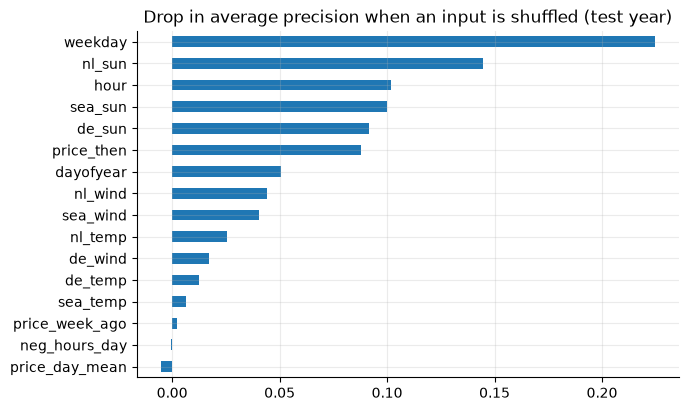

In [14]:
imp = permutation_importance(final["model"], pred[final["cols"]], pred.neg, scoring="average_precision", n_repeats=5, random_state=0)
pd.Series(imp.importances_mean, index=final["cols"]).sort_values().plot.barh(figsize=(7, 4.5), title="Drop in average precision when an input is shuffled (test year)")
plt.show()

## 7. Our own question: how far ahead does this work?

We repeat the whole experiment for forecasts made 1 to 7 days ahead, with the same inputs and the same training period.

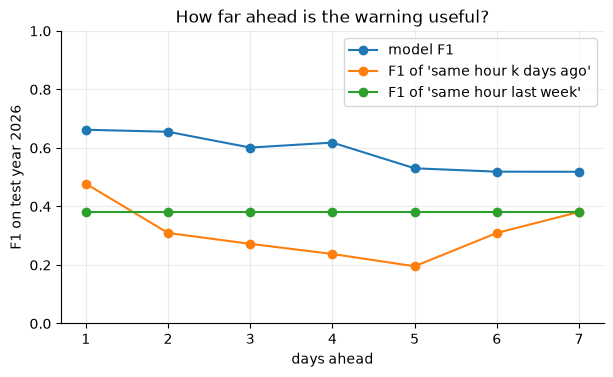

,model AP,model F1,F1 of 'same hour k days ago',F1 of 'same hour last week'
days ahead,,,,
1,0.772,0.662,0.478,0.381
2,0.736,0.655,0.309,0.381
3,0.667,0.601,0.272,0.381
4,0.619,0.618,0.238,0.381
5,0.583,0.530,0.196,0.381
6,0.539,0.519,0.309,0.381
7,0.541,0.519,0.381,0.381


In [15]:
lead_runs = {k: run(final["cols"], k) for k in LEADS}
rows = {}
for k, r in lead_runs.items():
    te = r["test"]
    rows[k] = {"model AP": average_precision_score(te.neg, te.prob), "model F1": f1_score(te.neg, te.flag), f"F1 of 'same hour k days ago'": f1_score(te.neg, te.price_then < 0), "F1 of 'same hour last week'": f1_score(te.neg, te.price_week_ago < 0)}
by_lead = pd.DataFrame(rows).T.rename_axis("days ahead")
by_lead.drop(columns="model AP").plot(marker="o", figsize=(7, 3.8), ylim=(0, 1), ylabel="F1 on test year 2026", title="How far ahead is the warning useful?")
plt.show()
by_lead.round(3)

## 8. Where does it fail?

First by group: does it work equally well for solar hours and night hours, weekends and weekdays?

In [16]:
day = pred.index.tz_convert(TZ)
groups = {
    "Daytime (09:00 to 17:59)": (day.hour >= 9) & (day.hour < 18),
    "Evening and night": (day.hour < 9) | (day.hour >= 18),
    "Weekend": day.day_of_week >= 5,
    "Weekday": day.day_of_week < 5,
    "April to September": (day.month >= 4) & (day.month <= 9),
    "October to March": (day.month < 4) | (day.month > 9),
}
group_table = pd.DataFrame({g: {"negative hours": int(pred.neg[m].sum()), **score(pred.neg[m], pred.flag[m])} for g, m in groups.items()}).T
group_table.round(3)

,negative hours,precision,recall,F1,warnings
Daytime (09:00 to 17:59),384.0,0.645,0.701,0.672,417.0
Evening and night,20.0,0.000,0.000,0.000,0.0
Weekend,266.0,0.742,0.714,0.728,256.0
Weekday,138.0,0.491,0.572,0.528,161.0
April to September,368.0,0.662,0.698,0.680,388.0
October to March,36.0,0.414,0.333,0.369,29.0


One more cut: how far below zero were the hours it missed? An hour at −0.01 EUR/MWh counts as negative,
but missing it costs almost nothing.

In [17]:
negative = pred[pred.neg == 1]
depth = pd.cut(negative.price, [-np.inf, -20, -1, 0], right=False, labels=["Below −20 EUR/MWh", "−20 to −1", "−1 to 0 (barely negative)"])
depth_table = negative.groupby(depth, observed=False).flag.agg(["size", "sum", "mean"]).set_axis(["negative hours", "caught", "share caught"], axis=1)
depth_table.round(3)

,negative hours,caught,share caught
price,,,
Below −20 EUR/MWh,70,63,0.900
−20 to −1,192,134,0.698
−1 to 0 (barely negative),142,72,0.507


Then the two worst days: the day with the most **missed** negative hours and the day with the most **false alarms**.
For each we also print the sunshine that was forecast two days ahead next to what the latest estimate says really happened.

            negative  missed  false_alarms  sun_forecast  sun_actual  de_wind_forecast  price_mean
date                                                                                              
2026-04-05      17.0    14.0           0.0           3.5         3.6              37.4        14.5
2026-05-03       0.0     0.0           6.0           3.0         1.4              25.0        89.8


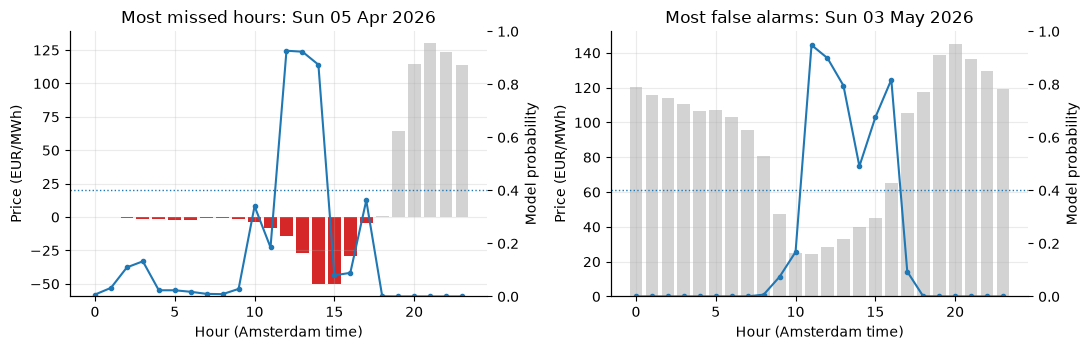

In [18]:
pred["date"] = day.date
per_day = pred.groupby("date").apply(lambda d: pd.Series({"negative": d.neg.sum(), "missed": (d.neg.astype(bool) & ~d.flag).sum(), "false_alarms": (~d.neg.astype(bool) & d.flag).sum(), "sun_forecast": d.nl_sun.sum() / 1000, "sun_actual": d.sun_actual.sum() / 1000, "de_wind_forecast": d.de_wind.mean() if "de_wind" in d else np.nan, "price_mean": d.price.mean()}), include_groups=False)
worst_miss, worst_false = per_day.missed.idxmax(), per_day.false_alarms.idxmax()
print(per_day.loc[[worst_miss, worst_false]].round(1).to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=False)
for ax, d, label in zip(axes, [worst_miss, worst_false], ["Most missed hours", "Most false alarms"]):
    one = pred[pred.date == d]
    hours = one.index.tz_convert(TZ).hour
    ax.bar(hours, one.price, color=np.where(one.price < 0, "tab:red", "lightgray"))
    ax.set(title=f"{label}: {d:%a %d %b %Y}", xlabel="Hour (Amsterdam time)", ylabel="Price (EUR/MWh)")
    ax2 = ax.twinx()
    ax2.plot(hours, one.prob, color="tab:blue", marker=".")
    ax2.axhline(final["thr"], color="tab:blue", ls=":", lw=1)
    ax2.set(ylim=(0, 1), ylabel="Model probability")
    ax2.grid(False)
plt.tight_layout()
plt.show()

## 9. Would it have saved money?

Two rough checks on the test year, using wholesale prices. They show whether the warnings point the right way.
They are not a prediction of anyone's bill.

**Check 1: switching off solar export.** A household with 10 solar panels (4 kWp) and a dynamic contract is paid
the hourly market price for power sent to the grid. In a negative hour, exporting costs money. Two days ahead they
plan to stop exporting in the warned hours. A correct warning avoids paying the negative price; a false alarm
throws away power that would have earned the positive price.
Assumption: production per hour ≈ sunshine (W/m²) ÷ 1000 × 4 kWp × 0.85.

In [19]:
kwh = pred.sun_actual / 1000 * 4 * 0.85
gain = -pred.price / 1000 * kwh  # euros gained by NOT exporting in that hour (negative when the price was positive)
policies = {
    "Same hour last week was negative": pred.price_week_ago < 0,
    f"Weekend and forecast sun > {SUN_CUT} W/m²": sunny_weekend(pred, SUN_CUT),
    "Model warning": pred.flag,
    "Perfect foresight": pred.neg.astype(bool),
}
export_table = pd.DataFrame({name: {"euros gained in test period": gain[flag].sum()} for name, flag in policies.items()}).T
export_table["share of perfect"] = export_table.iloc[:, 0] / export_table.iloc[-1, 0]
export_table.round(2)

,euros gained in test period,share of perfect
Same hour last week was negative,-7.77,-0.48
Weekend and forecast sun > 350 W/m²,-8.26,-0.51
Model warning,10.04,0.62
Perfect foresight,16.22,1.00


**Check 2: which day should I charge the car?** This is the decision that tomorrow's published prices cannot
answer. An electric-car owner needs one 40 kWh charge in the next three days and can do it between 11:00 and 15:00.
Every day we let each strategy pick one of the next three days, then look up what the power really cost.

- *Tomorrow*: always charge tomorrow (no forecast).
- *Sunniest day*: a rule with no AI. Pick the day with the most forecast sunshine between 11:00 and 15:00.
- *Model*: pick the day where the model expects the most negative hours between 11:00 and 15:00.
  Tomorrow uses the 1-day model, the day after the 2-day model, and so on. If no day beats tomorrow by more than
  0.1, charge tomorrow. (The 0.1 is a fixed choice. We did not tune it on the test year.)
- *Perfect*: pick the day that really was cheapest.

In [20]:
midday = lambda t: t[(t.index.tz_convert(TZ).hour >= 11) & (t.index.tz_convert(TZ).hour < 15)]
by_date = lambda s: s.groupby(s.index.tz_convert(TZ).date).mean()
cost = by_date(midday(pred).price)  # real average 11:00-15:00 price on each test day
chance = {k: by_date(midday(lead_runs[k]["test"]).prob) for k in (1, 2, 3)}  # the model's view, made k days before
sunshine = {k: by_date(midday(lead_runs[k]["test"]).nl_sun) for k in (1, 2, 3)}  # forecast sun, made k days before
picks = []
for today in pd.DatetimeIndex(cost.index)[:-3]:
    options = [(today + pd.Timedelta(days=k)).date() for k in (1, 2, 3)]
    p = [chance[k][d] for k, d in zip((1, 2, 3), options)]
    sun = [sunshine[k][d] for k, d in zip((1, 2, 3), options)]
    model_day = options[int(np.argmax(p))] if max(p) - p[0] > 0.1 else options[0]
    picks.append({"Tomorrow": cost[options[0]], "Sunniest day": cost[options[int(np.argmax(sun))]], "Model": cost[model_day], "Perfect": min(cost[d] for d in options), "waited": model_day != options[0]})
picks = pd.DataFrame(picks)
paid = picks.drop(columns="waited").mean()
per_charge = paid / 1000 * 40 * 1.21  # 40 kWh, plus 21% VAT
print(f"{len(picks)} decisions. The model chose to wait on {picks.waited.mean():.0%} of them.")
charge_table = pd.DataFrame({"average price paid (EUR/MWh)": paid, "euros per 40 kWh charge": per_charge, "saved vs tomorrow": per_charge["Tomorrow"] - per_charge})
charge_table.round(2)

314 decisions. The model chose to wait on 39% of them.


,average price paid (EUR/MWh),euros per 40 kWh charge,saved vs tomorrow
Tomorrow,61.03,2.95,0.00
Sunniest day,56.34,2.73,0.23
Model,45.36,2.20,0.76
Perfect,30.47,1.47,1.48


## 10. The live outlook

The same tested models, pointed at the real future: today's weather forecast for the next seven days and the
latest prices. This cell gives a different answer every time it runs, so it is not part of the test results.
In winter it will usually say "no negative hours", which is correct.

In [21]:
def live_outlook():
    today = pd.Timestamp.now(TZ).normalize()
    d = get_json(f"https://api.energy-charts.info/price?bzn=NL&start={today - pd.Timedelta(days=10):%Y-%m-%d}&end={today + pd.Timedelta(days=1):%Y-%m-%d}")
    recent = pd.Series(d["price"], index=pd.to_datetime(d["unix_seconds"], unit="s", utc=True)).dropna().resample("1h").mean()
    recent = recent.reindex(pd.date_range(recent.index[0], (today + pd.Timedelta(days=8)).tz_convert("UTC"), freq="1h"))
    cols = {}
    for place, (lat, lon) in PLACES.items():
        h = get_json(f"https://api.open-meteo.com/v1/forecast?latitude={lat}&longitude={lon}&hourly={','.join(WX)}&past_days=1&forecast_days=9&timezone=UTC")["hourly"]
        for v, short in WX.items():
            for k in [0, *LEADS]:  # today's forecast plays the role of the k-days-ahead forecast
                cols[f"{place}_{short}_d{k}"] = pd.Series(h[v], index=pd.to_datetime(h["time"], utc=True))
    out = []
    for k in LEADS:
        t = make_table(k, recent, pd.DataFrame(cols))
        t = t[t.index.tz_convert(TZ).normalize() == today + pd.Timedelta(days=k)]
        r = lead_runs[k]
        prob = r["model"].predict_proba(t[r["cols"]])[:, 1]
        out.append({"date": f"{today + pd.Timedelta(days=k):%Y-%m-%d}", "days_ahead": k, "threshold": round(float(r["thr"]), 2), "hours": t.index.tz_convert(TZ).hour.tolist(), "prob": prob.round(3).tolist(), "sun": t.nl_sun.round().tolist()})
    return {"made": f"{pd.Timestamp.now(TZ):%Y-%m-%d %H:%M}", "days": out}


try:
    live = live_outlook()
    for d in live["days"]:
        warned = [h for h, p in zip(d["hours"], d["prob"]) if p >= d["threshold"]]
        print(d["date"], f"({d['days_ahead']} days ahead): highest chance {max(d['prob'], default=0):.0%};", f"warning for hours {warned}" if warned else "no warning")
except Exception as e:  # no internet, or a data source is down: the rest of the notebook still works
    live = None
    print("Live outlook skipped:", e)

2026-11-16 (1 days ahead): highest chance 0%; no warning
2026-11-17 (2 days ahead): highest chance 0%; no warning
2026-11-18 (3 days ahead): highest chance 0%; no warning
2026-11-19 (4 days ahead): highest chance 0%; no warning
2026-11-20 (5 days ahead): highest chance 0%; no warning
2026-11-21 (6 days ahead): highest chance 0%; no warning
2026-11-22 (7 days ahead): highest chance 0%; no warning


## 11. Save everything the demo page shows

The demo page (`demo/index.html`) does no modelling of its own. It only draws the numbers saved here,
so what you see in the demo is exactly what this notebook measured. For its "pretend today is" view we also
save the warnings made 3 to 7 days ahead, from the same runs as the days-ahead chart in section 7.

In [22]:
SHOWN = range(2, 8)  # the demo shows warnings made 2 to 7 days ahead
ahead = {k: lead_runs[k]["test"][["prob", "flag"]].reindex(pred.index) for k in SHOWN}  # line up with the main test table
assert (ahead[2].flag == pred.flag).all(), "the 2-day run should be the same as the final model"


def per_day(d):
    return {
        "hours": d.index.tz_convert(TZ).hour.tolist(),
        "price": d.price.round(1).tolist(),
        "last_week": (d.price_week_ago < 0).astype(int).tolist(),
        "sun_forecast": d.nl_sun.round().tolist(),
        "sun_actual": d.sun_actual.round().tolist(),
        # for each number of days ahead: the chance per hour in whole percent, and the warnings as a string of 0s and 1s
        "pct": {k: [None if np.isnan(x) else int(round(float(x) * 100)) for x in a.prob[d.index]] for k, a in ahead.items()},
        "warn": {k: "".join("1" if f == True else "0" for f in a.flag[d.index]) for k, a in ahead.items()},
    }


export = {
    "threshold": round(float(final["thr"]), 2),
    "test_period": [str(pred.date.min()), str(pred.date.max())],
    "counts": {"train_hours": len(train) + len(val), "test_hours": len(pred), "test_negative": int(pred.neg.sum())},
    "results": results.round(3).reset_index(names="name").to_dict("records"),
    "by_lead": by_lead.round(3).reset_index().set_axis(["days_ahead", "model_ap", "model_f1", "same_hour_f1", "last_week_f1"], axis=1).to_dict("records"),
    "worst": {"missed": str(worst_miss), "false_alarms": str(worst_false)},
    "groups": group_table.round(3).reset_index(names="name").to_dict("records"),
    "depth": depth_table.round(3).reset_index(names="name").to_dict("records"),
    "ablation": ablation.round(3).reset_index(names="name").to_dict("records"),
    "money": {"export": export_table.round(2).reset_index(names="name").to_dict("records"), "charge": charge_table.round(2).reset_index(names="name").to_dict("records")},
    "days": {str(date): per_day(d) for date, d in pred.groupby("date")},
}
Path("demo").mkdir(exist_ok=True)
Path("demo/data.js").write_text("window.ONDER_NUL = " + json.dumps(export, separators=(",", ":")) + ";\n")
print(f"Saved demo/data.js ({Path('demo/data.js').stat().st_size / 1000:.0f} kB, {len(export['days'])} test days)")

Saved demo/data.js (353 kB, 317 test days)
